Step 1: Environment Setup, Fix Pillow & Java 21


In [ ]:
# ==============================================================================
# STEP 1: SETUP ENVIRONMENT, FIX PILLOW & JAVA 21
# ==============================================================================
import os

print("======================================================================")
print(" 1. INSTALLING JAVA 21 & RAG PACKAGES FOR LLAMA-3 + BGE")
print("======================================================================")
!apt-get update -q
!apt-get install -y openjdk-21-jdk -q
!update-java-alternatives --set java-1.21.0-openjdk-amd64
!pip uninstall -y pillow -q
!pip install "pillow==10.4.0" -q
!pip install pyserini faiss-gpu sentence-transformers datasets accelerate bitsandbytes -q

os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-21-openjdk-amd64"
os.environ["JVM_PATH"] = "/usr/lib/jvm/java-21-openjdk-amd64/lib/server/libjvm.so"

from google.colab import drive
drive.mount('/content/drive', force_remount=True)

print("\n✅ Step 1 Complete! Kernel restarting for clean memory...")
os._exit(0)

 1. INSTALLING JAVA 21 & RAG PACKAGES FOR LLAMA-3 + BGE
Get:1 https://cloud.r-project.org/bin/linux/ubuntu jammy-cran40/ InRelease [3,632 B]
Get:2 https://cli.github.com/packages stable InRelease [3,917 B]
Get:3 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2204/x86_64  InRelease [1,581 B]
Get:4 https://cloud.r-project.org/bin/linux/ubuntu jammy-cran40/ Packages [105 kB]
Get:5 https://cli.github.com/packages stable/main amd64 Packages [356 B]
Get:6 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2204/x86_64  Packages [2,899 kB]
Hit:7 http://archive.ubuntu.com/ubuntu jammy InRelease
Get:8 http://archive.ubuntu.com/ubuntu jammy-updates InRelease [128 kB]
Get:9 http://security.ubuntu.com/ubuntu jammy-security InRelease [129 kB]
Get:10 https://r2u.stat.illinois.edu/ubuntu jammy InRelease [6,555 B]
Get:11 https://r2u.stat.illinois.edu/ubuntu jammy/main all Packages [10.7 MB]
Get:12 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu jammy InRelease [18.1 k

Step 2: Load Substrates (Lucene BM25 + BGE FAISS Engine)


In [ ]:
# ==============================================================================
# STEP 2: LOAD KNOWLEDGE SUBSTRATES (BM25 + BGE FAISS)
# Alignment: Proposal Section 3.5.1 & Table 3.2
# ==============================================================================
import os
import json
import torch
import faiss
from pyserini.search.lucene import LuceneSearcher

os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-21-openjdk-amd64"
os.environ["JVM_PATH"] = "/usr/lib/jvm/java-21-openjdk-amd64/lib/server/libjvm.so"

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"[INFO] Active Hardware Accelerator: {device.upper()}")

# Directory Paths
BASE_DIR = '/content/drive/My Drive/Objective 1'
BM25_DIR = os.path.join(BASE_DIR, 'indices', 'bm25')
FAISS_BGE_DIR = os.path.join(BASE_DIR, 'indices', 'faiss_bge_shards')

# 1. Load Lexical BM25
bm25_searcher = LuceneSearcher(BM25_DIR)
print(f"✅ [SUBSTRATE 1/2] Lucene BM25 Active ({bm25_searcher.num_docs:,} docs)")

# 2. Load Multi-Shard BGE FAISS Engine
class FullBGEFAISSSearcher:
    def __init__(self, shards_dir):
        self.shards = []
        self.id_maps = []
        index_files = sorted([f for f in os.listdir(shards_dir) if f.endswith('.index')])
        for idx_f in index_files:
            shard_num = idx_f.replace('kilt_bge_shard_', '').replace('.index', '')
            map_f = f"bge_map_shard_{shard_num}.json"

            idx_path = os.path.join(shards_dir, idx_f)
            map_path = os.path.join(shards_dir, map_f)

            index = faiss.read_index(idx_path)
            with open(map_path, 'r', encoding='utf-8') as f:
                id_map = json.load(f)
            self.shards.append(index)
            self.id_maps.append(id_map)

        print(f"✅ [SUBSTRATE 2/2] FAISS BGE Dense Active ({len(self.shards)} shards, ~21.1M passages)")

    def search(self, query_vector, top_k=5):
        all_candidates = []
        for index, id_map in zip(self.shards, self.id_maps):
            scores, indices = index.search(query_vector, top_k)
            for score, idx in zip(scores[0], indices[0]):
                if idx != -1:
                    cid = id_map.get(str(idx), f"idx_{idx}")
                    all_candidates.append((float(score), cid))
        all_candidates.sort(key=lambda x: x[0], reverse=True)
        return all_candidates[:top_k]

bge_faiss_searcher = FullBGEFAISSSearcher(FAISS_BGE_DIR)

[INFO] Active Hardware Accelerator: CUDA
✅ [SUBSTRATE 1/2] Lucene BM25 Active (21,113,601 docs)
✅ [SUBSTRATE 2/2] FAISS BGE Dense Active (6 shards, ~21.1M passages)


Step 3: Load BGE Query Encoder & LLaMA-3-8B Generator Backbone


In [ ]:
# ==============================================================================
# STEP 3: LOAD BGE QUERY ENCODER & LLAMA-3-8B BACKBONE
# Alignment: Proposal Table 3.2
# ==============================================================================
import torch
import torch.nn.functional as F
from sentence_transformers import SentenceTransformer
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig

# 1. Load BGE Dense Query Encoder
BGE_MODEL_NAME = "BAAI/bge-large-en-v1.5"
print(f"[INFO] Loading BGE Query Encoder ({BGE_MODEL_NAME})...")
bge_query_encoder = SentenceTransformer(BGE_MODEL_NAME, device=device)

# MiniLM Encoder for Policy Network Vectors
query_encoder = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2", device=device)

# BGE Query Encoding Function
def encode_dense_query_bge(q_text):
    emb = bge_query_encoder.encode([q_text], convert_to_numpy=True, normalize_embeddings=True)
    return emb.astype('float32')

# 2. Load LLaMA-3-8B-Instruct Backbone (Open-Access Mirror, 4-bit NF4)
LLAMA_BACKBONE = "NousResearch/Meta-Llama-3-8B-Instruct"
print(f"\n[INFO] Loading LLaMA Backbone ({LLAMA_BACKBONE})...")

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16
)

llama_tokenizer = AutoTokenizer.from_pretrained(LLAMA_BACKBONE, use_fast=True)
if llama_tokenizer.pad_token is None:
    llama_tokenizer.pad_token = llama_tokenizer.eos_token

llama_model = AutoModelForCausalLM.from_pretrained(
    LLAMA_BACKBONE,
    quantization_config=bnb_config,
    device_map="auto"
)
llama_model.eval()

print("\n✅ LLaMA-3-8B Backbone & BGE-Large Encoder Successfully Loaded!")

[INFO] Loading BGE Query Encoder (BAAI/bge-large-en-v1.5)...


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/94.6k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/187 [00:00<?, ?B/s]


✅ LLaMA-3-8B Backbone & BGE-Large Encoder Successfully Loaded!


Step 4: Load LARO Policy Net & Epistemic Signal Extractor for LLaMA-3


In [ ]:
# ==============================================================================
# STEP 4: LOAD LARO POLICY CONTROLLER & LLAMA EPISTEMIC EXTRACTOR
# Alignment: Proposal Section 3.2.1
# ==============================================================================
import os
import json
import time
import numpy as np
import torch.nn as nn

# 1. Define LARO Policy MLP
class LARO4ClassPolicyMLP(nn.Module):
    def __init__(self, input_dim, num_classes=4):
        super(LARO4ClassPolicyMLP, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, 256), nn.LayerNorm(256), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(256, 128), nn.LayerNorm(128), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(128, num_classes)
        )
    def forward(self, x):
        return self.network(x)

# Load Policy Controller
POLICY_MODEL_PATH = os.path.join(BASE_DIR, 'laro_supervision', 'laro_4class_policy_controller.pt')
checkpoint = torch.load(POLICY_MODEL_PATH, map_location=device, weights_only=False)
scaler = checkpoint['scaler']
label_map = checkpoint['label_map']
inv_label_map = {v: k for k, v in label_map.items()}

policy_net = LARO4ClassPolicyMLP(input_dim=checkpoint['input_dim'], num_classes=4).to(device)
policy_net.load_state_dict(checkpoint['model_state_dict'])
policy_net.eval()

# 2. Epistemic Extractor for LLaMA-3
def extract_causal_epistemic_signals_llama(query_text):
    messages = [{"role": "user", "content": query_text}]
    prompt = llama_tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    inputs = llama_tokenizer([prompt], return_tensors="pt").to(device)

    with torch.no_grad():
        outputs = llama_model(**inputs)
        logits = outputs.logits.float()

    input_ids = inputs["input_ids"]
    if input_ids.shape[1] > 1:
        shift_logits = logits[..., :-1, :].contiguous()
        shift_labels = input_ids[..., 1:].contiguous()
        loss_fct = torch.nn.CrossEntropyLoss()
        loss = loss_fct(shift_logits.view(-1, shift_logits.size(-1)), shift_labels.view(-1))
        perplexity = torch.exp(loss).item() if not torch.isnan(loss) else 50.0
    else:
        perplexity = 50.0

    probs = F.softmax(logits, dim=-1)
    top2_probs, _ = torch.topk(probs, k=2, dim=-1)
    margin = (top2_probs[0, :, 0] - top2_probs[0, :, 1]).mean().item()

    log_probs = F.log_softmax(logits, dim=-1)
    target_log_probs = log_probs[0, range(input_ids.shape[1]-1), input_ids[0, 1:]] if input_ids.shape[1] > 1 else log_probs[0, 0, 0]
    dispersion = torch.std(target_log_probs).item() if target_log_probs.numel() > 1 else 0.0

    return {
        "sigma_ppl": round(perplexity, 4),
        "sigma_attn_entropy": 1.05,
        "log_prob_dispersion": round(dispersion, 4),
        "top_margin": round(margin, 4)
    }

def is_query_suboptimal(query_text, signals):
    words = query_text.strip().split()
    pronouns = ['it', 'they', 'them', 'this', 'that', 'he', 'she']
    contains_pronoun = any(p in query_text.lower().split() for p in pronouns)
    is_vague = len(words) < 5 and signals['sigma_ppl'] > 50.0
    return contains_pronoun or is_vague

def rewrite_query_llama(query_text):
    messages = [
        {"role": "system", "content": "You are a search query reformulator. Rewrite the query to be explicit, entity-rich, and clear for Wikipedia search. Output ONLY the rewritten query."},
        {"role": "user", "content": f"Query: {query_text}"}
    ]
    prompt = llama_tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    inputs = llama_tokenizer([prompt], return_tensors="pt").to(device)

    with torch.no_grad():
        out = llama_model.generate(
            inputs.input_ids,
            attention_mask=inputs.attention_mask,
            max_new_tokens=30,
            do_sample=False,
            pad_token_id=llama_tokenizer.eos_token_id
        )
        gen = [output_ids[len(input_ids):] for input_ids, output_ids in zip(inputs.input_ids, out)]
        rewritten = llama_tokenizer.batch_decode(gen, skip_special_tokens=True)[0].strip()
        return rewritten.strip('"').strip("'").strip()

print("✅ Step 4 Complete: LARO Policy Net & LLaMA-3 Extractor Ready.")

✅ Step 4 Complete: LARO Policy Net & LLaMA-3 Extractor Ready.


Step 5: Main LLaMA-3 + BGE Execution Pipeline


In [ ]:
# ==============================================================================
# STEP 5: EXECUTE LLAMA-3 + BGE PIPELINE
# ==============================================================================

def execute_llama_bge_pipeline(query_text, ppl_threshold=80.0, margin_threshold=0.55):
    t_start = time.time()
    signals = extract_causal_epistemic_signals_llama(query_text)
    is_low_uncertainty = (signals['sigma_ppl'] <= ppl_threshold) and (signals['top_margin'] >= margin_threshold)

    if is_low_uncertainty:
        pipeline_tier = "TIER 1 FAST PATH (Direct Generation)"
        action_executed = "SKIP"
        retrieved_k = 0
        search_query = query_text
        retrieved_passages = []
    else:
        pipeline_tier = "TIER 2 DEEP RESEARCH PATH (LARO Control Layer)"
        q_emb = query_encoder.encode([query_text], convert_to_numpy=True)
        cues_arr = np.array([[signals['sigma_ppl'], signals['sigma_attn_entropy'], signals['log_prob_dispersion'], signals['top_margin']]])
        cues_scaled = scaler.transform(cues_arr)
        x_input = torch.tensor(np.hstack([q_emb, cues_scaled]), dtype=torch.float32).to(device)

        with torch.no_grad():
            logits = policy_net(x_input)
            pred_action_id = int(torch.argmax(logits, dim=1).item())

        action_name = inv_label_map[pred_action_id]
        needs_rewrite = is_query_suboptimal(query_text, signals)

        if needs_rewrite or action_name == "REWRITE_RETRIEVE":
            action_executed = "REWRITE_RETRIEVE"
            search_query = rewrite_query_llama(query_text)
        else:
            search_query = query_text
            action_executed = action_name
            if signals['sigma_ppl'] > 25.0 and action_executed == "SKIP":
                action_executed = "SEMANTIC_DENSE"

        retrieved_k = 5
        retrieved_passages = []

        if action_executed == "LEXICAL_BM25":
            hits = bm25_searcher.search(search_query, k=retrieved_k)
            for h in hits:
                d = bm25_searcher.doc(h.docid)
                if d:
                    try: retrieved_passages.append(json.loads(d.raw()).get("contents", d.contents()))
                    except: retrieved_passages.append(d.contents())
        elif action_executed in ["SEMANTIC_DENSE", "REWRITE_RETRIEVE"]:
            q_vec = encode_dense_query_bge(search_query) # Calls BGE Dense Encoder
            top_matches = bge_faiss_searcher.search(q_vec, top_k=retrieved_k)
            for score, cid in top_matches:
                doc_obj = bm25_searcher.doc(cid)
                if doc_obj:
                    try: retrieved_passages.append(json.loads(doc_obj.raw()).get("contents", doc_obj.contents()))
                    except: retrieved_passages.append(doc_obj.contents())

    if retrieved_passages:
        clean_context = "\n\n".join([f"Document {i+1}: {str(p).strip()}" for i, p in enumerate(retrieved_passages)])[:1500]
        messages = [
            {"role": "system", "content": "You are a precise AI assistant. Answer directly and concisely based ONLY on the provided documents. If the exact answer is not provided, state that clearly."},
            {"role": "user", "content": f"Documents:\n{clean_context}\n\nQuestion: {query_text}"}
        ]
    else:
        messages = [
            {"role": "system", "content": "You are a precise, factual AI assistant. Answer concisely."},
            {"role": "user", "content": query_text}
        ]

    prompt_text = llama_tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    model_inputs = llama_tokenizer([prompt_text], return_tensors="pt").to(device)

    with torch.no_grad():
        generated_ids = llama_model.generate(
            model_inputs.input_ids,
            attention_mask=model_inputs.attention_mask,
            max_new_tokens=80,
            do_sample=False,
            pad_token_id=llama_tokenizer.eos_token_id
        )
        generated_ids = [output_ids[len(input_ids):] for input_ids, output_ids in zip(model_inputs.input_ids, generated_ids)]
        response = llama_tokenizer.batch_decode(generated_ids, skip_special_tokens=True)[0].strip()

    elapsed = round(time.time() - t_start, 2)

    print("\n" + "="*85)
    print(f" RAW USER QUERY: \"{query_text}\"")
    print("="*85)
    print(f"Pipeline Route      : {pipeline_tier}")
    print(f"Action Executed     : [{action_executed}]")
    print(f"Retrieved Count     : Fetched {len(retrieved_passages)} docs")
    print(f"Search Query Used   : \"{search_query}\"")
    print(f"\n✨ LLAMA-3-8B + BGE GROUNDED ANSWER (Latency: {elapsed}s):\n{response}")

print("✅ Step 5 Loaded Successfully! Ready for Benchmark Evaluation.")

✅ Step 5 Loaded Successfully! Ready for Benchmark Evaluation.


Step 6: Evaluate LLaMA-3 + BGE on NQ, HotpotQA & TriviaQA & Print Questions


In [ ]:
# ==============================================================================
# STEP 6: EVALUATE LLAMA-3 + BGE ON BENCHMARKS & PRINT DETAILED QUESTIONS
# Alignment: Proposal Table 3.1 & Section 3.7
# ==============================================================================
from tqdm import tqdm
from datasets import load_dataset

llama_bge_eval_results = []

# Load Oracle Supervision Lookup
SUPERVISION_PATH = os.path.join(BASE_DIR, 'laro_supervision', 'laro_oracle_supervision_4class_2000.jsonl')
oracle_records = []
if os.path.exists(SUPERVISION_PATH):
    with open(SUPERVISION_PATH, 'r', encoding='utf-8') as f:
        for line in f:
            oracle_records.append(json.loads(line))

oracle_lookup = {r["query"].strip().lower(): r["oracle_action"] for r in oracle_records} if oracle_records else {}

# Metric Helpers
def calc_exact_match(prediction_text, ground_truths):
    pred_clean = str(prediction_text).lower().strip()
    for gt in ground_truths:
        gt_clean = str(gt).lower().strip()
        if gt_clean and (gt_clean in pred_clean or pred_clean in gt_clean):
            return 1.0
    return 0.0

def calc_token_f1(prediction_text, ground_truths):
    pred_tokens = str(prediction_text).lower().strip().split()
    if not pred_tokens: return 0.0
    max_f1 = 0.0
    for gt in ground_truths:
        gt_tokens = str(gt).lower().strip().split()
        common = set(pred_tokens) & set(gt_tokens)
        if not common: continue
        precision = len(common) / len(pred_tokens)
        recall = len(common) / len(gt_tokens)
        f1 = 2 * (precision * recall) / (precision + recall)
        if f1 > max_f1: max_f1 = f1
    return max_f1

benchmarks = [
    ("1_NQ", "Natural Questions (NQ)", "facebook/kilt_tasks", "nq", "input", "output"),
    ("2_HotpotQA", "HotpotQA (Multi-hop)", "facebook/kilt_tasks", "hotpotqa", "input", "output"),
    ("3_TriviaQA", "TriviaQA (Open-domain)", "mandarjoshi/trivia_qa", "rc.nocontext", "question", "answer")
]

for order_tag, ds_label, path, config, q_key, a_key in benchmarks:
    print(f"\n" + "="*80)
    print(f" ➜ INGESTING VALIDATION ITEMS: {ds_label.upper()}")
    print("="*80)

    ds = load_dataset(path, config, split="validation")
    items = []

    for i, item in enumerate(ds):
        if i >= 20: break  # 20 official validation items per dataset
        q_text = item.get(q_key, "")
        if ds_label.startswith("TriviaQA"):
            ans_dict = item.get(a_key, {})
            gts = list(set([a for a in [ans_dict.get("value", "")] + ans_dict.get("aliases", []) if str(a).strip()]))
        else:
            gts = [alt.get("answer", "") for alt in item.get(a_key, []) if alt.get("answer")]
        if q_text and gts:
            items.append({"query": q_text, "ground_truth": gts})

    for sample in tqdm(items, desc=f"Evaluating LLaMA+BGE on {ds_label}"):
        q_text = sample["query"]
        gts = sample["ground_truth"]
        t0_start = time.time()

        signals = extract_causal_epistemic_signals_llama(q_text)
        q_emb = query_encoder.encode([q_text], convert_to_numpy=True)
        cues_arr = np.array([[signals['sigma_ppl'], signals['sigma_attn_entropy'], signals['log_prob_dispersion'], signals['top_margin']]])
        cues_scaled = scaler.transform(cues_arr)
        x_input = torch.tensor(np.hstack([q_emb, cues_scaled]), dtype=torch.float32).to(device)

        with torch.no_grad():
            logits = policy_net(x_input)
            pred_action_id = int(torch.argmax(logits, dim=1).item())

        predicted_action = inv_label_map[pred_action_id]
        oracle_target_action = oracle_lookup.get(q_text.strip().lower(), predicted_action)
        is_orchestration_correct = 1.0 if predicted_action == oracle_target_action else 0.0

        needs_rewrite = is_query_suboptimal(q_text, signals)
        if needs_rewrite or predicted_action == "REWRITE_RETRIEVE":
            action_executed = "REWRITE_RETRIEVE"
            search_query = rewrite_query_llama(q_text)
        else:
            search_query = q_text
            action_executed = predicted_action
            if signals['sigma_ppl'] > 25.0 and action_executed == "SKIP":
                action_executed = "SEMANTIC_DENSE"

        retrieved_k = 0 if action_executed == "SKIP" else 5
        retrieved_passages = []

        if retrieved_k > 0:
            if action_executed == "LEXICAL_BM25":
                hits = bm25_searcher.search(search_query, k=retrieved_k)
                for h in hits:
                    d = bm25_searcher.doc(h.docid)
                    if d:
                        try: retrieved_passages.append(json.loads(d.raw()).get("contents", d.contents()))
                        except: retrieved_passages.append(d.contents())
            elif action_executed in ["SEMANTIC_DENSE", "REWRITE_RETRIEVE"]:
                q_vec = encode_dense_query_bge(search_query) # Calls BGE Dense Encoder
                top_matches = bge_faiss_searcher.search(q_vec, top_k=retrieved_k)
                for score, cid in top_matches:
                    doc_obj = bm25_searcher.doc(cid)
                    if doc_obj:
                        try: retrieved_passages.append(json.loads(doc_obj.raw()).get("contents", doc_obj.contents()))
                        except: retrieved_passages.append(doc_obj.contents())

        if retrieved_passages:
            clean_context = "\n\n".join([f"Document {i+1}: {str(p).strip()}" for i, p in enumerate(retrieved_passages)])[:1500]
            messages = [
                {"role": "system", "content": "You are a precise AI assistant. Answer directly and concisely based ONLY on the provided documents. If the exact answer is not provided, state that clearly."},
                {"role": "user", "content": f"Documents:\n{clean_context}\n\nQuestion: {q_text}"}
            ]
        else:
            messages = [
                {"role": "system", "content": "You are a precise, factual AI assistant. Answer concisely."},
                {"role": "user", "content": q_text}
            ]

        prompt_text = llama_tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
        model_inputs = llama_tokenizer([prompt_text], return_tensors="pt").to(device)

        with torch.no_grad():
            generated_ids = llama_model.generate(
                model_inputs.input_ids,
                attention_mask=model_inputs.attention_mask,
                max_new_tokens=80,
                do_sample=False,
                pad_token_id=llama_tokenizer.eos_token_id
            )
            generated_ids = [output_ids[len(input_ids):] for input_ids, output_ids in zip(model_inputs.input_ids, generated_ids)]
            generated_answer = llama_tokenizer.batch_decode(generated_ids, skip_special_tokens=True)[0].strip()

        elapsed_time = round(time.time() - t0_start, 2)
        em = calc_exact_match(generated_answer, gts)
        f1 = calc_token_f1(generated_answer, gts)
        sparsity_pct = (1.0 - (retrieved_k / 10.0)) * 100.0

        llama_bge_eval_results.append({
            "dataset_order": order_tag,
            "dataset": ds_label,
            "query": q_text,
            "oracle_action": oracle_target_action,
            "predicted_action": predicted_action,
            "action_executed": action_executed,
            "is_orchestration_correct": is_orchestration_correct,
            "retrieved_k": retrieved_k,
            "sparsity_pct": sparsity_pct,
            "exact_match": em,
            "token_f1": f1,
            "latency_sec": elapsed_time,
            "generated_answer": generated_answer,
            "ground_truth": gts[0]
        })

# Save Results CSV
df_llama_bge = pd.DataFrame(llama_bge_eval_results)
results_path = os.path.join(BASE_DIR, 'results', 'llama3_bge_objective1_benchmark_results.csv')
os.makedirs(os.path.dirname(results_path), exist_ok=True)
df_llama_bge.to_csv(results_path, index=False)

# Print Summary
print("\n" + "="*85)
print(" 🚀 LLAMA-3-8B + BGE BENCHMARK EVALUATION SUMMARY (OBJECTIVE 1 / LARO)")
print("="*85)

for ds_order in sorted(df_llama_bge['dataset_order'].unique()):
    sub_df = df_llama_bge[df_llama_bge['dataset_order'] == ds_order]
    ds_title = sub_df['dataset'].iloc[0]
    print(f"\n📊 {ds_title.upper()}:")
    print(f"    ➜ Exact Match (EM)      : {sub_df['exact_match'].mean()*100:.2f}%")
    print(f"    ➜ Token F1 Score        : {sub_df['token_f1'].mean()*100:.2f}%")
    print(f"    ➜ Orchestration Acc    : {sub_df['is_orchestration_correct'].mean()*100:.2f}%")
    print(f"    ➜ Sparsity Saved       : {sub_df['sparsity_pct'].mean():.2f}%")
    print(f"    ➜ Mean Query Latency   : {sub_df['latency_sec'].mean():.2f}s")

# Print Questions Breakdown
print("\n" + "="*100)
print(" 📋 DETAILED QUESTION-BY-QUESTION EVALUATION BREAKDOWN (LLAMA-3 + BGE)")
print("="*100)

for ds_order in sorted(df_llama_bge['dataset_order'].unique()):
    sub_df = df_llama_bge[df_llama_bge['dataset_order'] == ds_order].reset_index(drop=True)
    ds_title = sub_df['dataset'].iloc[0]

    print("\n" + "#"*100)
    print(f" 📌 DATASET: {ds_title.upper()}")
    print("#"*100)

    for idx, row in sub_df.iterrows():
        status = "✅ EXACT MATCH" if row['exact_match'] == 1.0 else "❌ MISMATCH"
        print(f"\n[{idx+1:02d}] QUESTION: {row['query']}")
        print(f"     ├── Action Executed  : [{row['action_executed']}] (Predicted: {row['predicted_action']} | Oracle: {row['oracle_action']})")
        print(f"     ├── Ground Truth     : \"{row['ground_truth']}\"")
        print(f"     ├── LLaMA+BGE Answer : \"{row['generated_answer']}\"")
        print(f"     └── Metric           : {status} | Token F1: {row['token_f1']*100:.2f}% | Latency: {row['latency_sec']}s")

print(f"\n✅ All LLaMA-3 + BGE evaluations complete and saved to '{results_path}'!")


 ➜ INGESTING VALIDATION ITEMS: NATURAL QUESTIONS (NQ)


README.md:   0%|          | 0.00/35.5k [00:00<?, ?B/s]

nq/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 14.0MB            

nq/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

nq/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 2.43MB            

...

Generating train split:   0%|          | 0/138384 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/17944 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/17210 [00:00<?, ? examples/s]

Evaluating LLaMA+BGE on TriviaQA (Open-domain): 100%|██████████| 20/20 [02:22<00:00,  7.11s/it]


NameError: name 'pd' is not defined

In [ ]:
# ==============================================================================
# DISPLAY SUMMARY, PRINT DETAILED QUESTIONS & SAVE CSV
# ==============================================================================
import os
import pandas as pd

BASE_DIR = '/content/drive/My Drive/Objective 1'

# 1. Create DataFrame from Evaluation Log
df_llama_bge = pd.DataFrame(llama_bge_eval_results)

# 2. Print Summary Metrics
print("="*85)
print(" 🚀 LLAMA-3-8B + BGE BENCHMARK EVALUATION SUMMARY (OBJECTIVE 1 / LARO)")
print("="*85)

for ds_order in sorted(df_llama_bge['dataset_order'].unique()):
    sub_df = df_llama_bge[df_llama_bge['dataset_order'] == ds_order]
    ds_title = sub_df['dataset'].iloc[0]
    print(f"\n📊 {ds_title.upper()}:")
    print(f"    ➜ Exact Match (EM)      : {sub_df['exact_match'].mean()*100:.2f}%")
    print(f"    ➜ Token F1 Score        : {sub_df['token_f1'].mean()*100:.2f}%")
    print(f"    ➜ Orchestration Acc    : {sub_df['is_orchestration_correct'].mean()*100:.2f}%")
    print(f"    ➜ Sparsity Saved       : {sub_df['sparsity_pct'].mean():.2f}%")
    print(f"    ➜ Mean Query Latency   : {sub_df['latency_sec'].mean():.2f}s")

# 3. Save CSV to Google Drive
results_path = os.path.join(BASE_DIR, 'results', 'llama3_bge_objective1_benchmark_results.csv')
os.makedirs(os.path.dirname(results_path), exist_ok=True)
df_llama_bge.to_csv(results_path, index=False)
print(f"\n✅ Successfully saved full LLaMA-3 + BGE results to:\n   '{results_path}'")

# 4. Print Question-by-Question Breakdown
print("\n" + "="*100)
print(" 📋 DETAILED QUESTION-BY-QUESTION EVALUATION BREAKDOWN (LLAMA-3 + BGE)")
print("="*100)

for ds_order in sorted(df_llama_bge['dataset_order'].unique()):
    sub_df = df_llama_bge[df_llama_bge['dataset_order'] == ds_order].reset_index(drop=True)
    ds_title = sub_df['dataset'].iloc[0]

    print("\n" + "#"*100)
    print(f" 📌 DATASET: {ds_title.upper()}")
    print("#"*100)

    for idx, row in sub_df.iterrows():
        status = "✅ EXACT MATCH" if row['exact_match'] == 1.0 else "❌ MISMATCH"
        print(f"\n[{idx+1:02d}] QUESTION: {row['query']}")
        print(f"     ├── Action Executed  : [{row['action_executed']}] (Predicted: {row['predicted_action']} | Oracle: {row['oracle_action']})")
        print(f"     ├── Ground Truth     : \"{row['ground_truth']}\"")
        print(f"     ├── LLaMA+BGE Answer : \"{row['generated_answer']}\"")
        print(f"     └── Metric           : {status} | Token F1: {row['token_f1']*100:.2f}% | Latency: {row['latency_sec']}s")

 🚀 LLAMA-3-8B + BGE BENCHMARK EVALUATION SUMMARY (OBJECTIVE 1 / LARO)

📊 NATURAL QUESTIONS (NQ):
    ➜ Exact Match (EM)      : 60.00%
    ➜ Token F1 Score        : 13.46%
    ➜ Orchestration Acc    : 70.00%
    ➜ Sparsity Saved       : 50.00%
    ➜ Mean Query Latency   : 14.67s

📊 HOTPOTQA (MULTI-HOP):
    ➜ Exact Match (EM)      : 45.00%
    ➜ Token F1 Score        : 4.04%
    ➜ Orchestration Acc    : 90.00%
    ➜ Sparsity Saved       : 50.00%
    ➜ Mean Query Latency   : 12.61s

📊 TRIVIAQA (OPEN-DOMAIN):
    ➜ Exact Match (EM)      : 40.00%
    ➜ Token F1 Score        : 9.37%
    ➜ Orchestration Acc    : 65.00%
    ➜ Sparsity Saved       : 50.00%
    ➜ Mean Query Latency   : 7.11s

✅ Successfully saved full LLaMA-3 + BGE results to:
   '/content/drive/My Drive/Objective 1/results/llama3_bge_objective1_benchmark_results.csv'

 📋 DETAILED QUESTION-BY-QUESTION EVALUATION BREAKDOWN (LLAMA-3 + BGE)

##########################################################################################

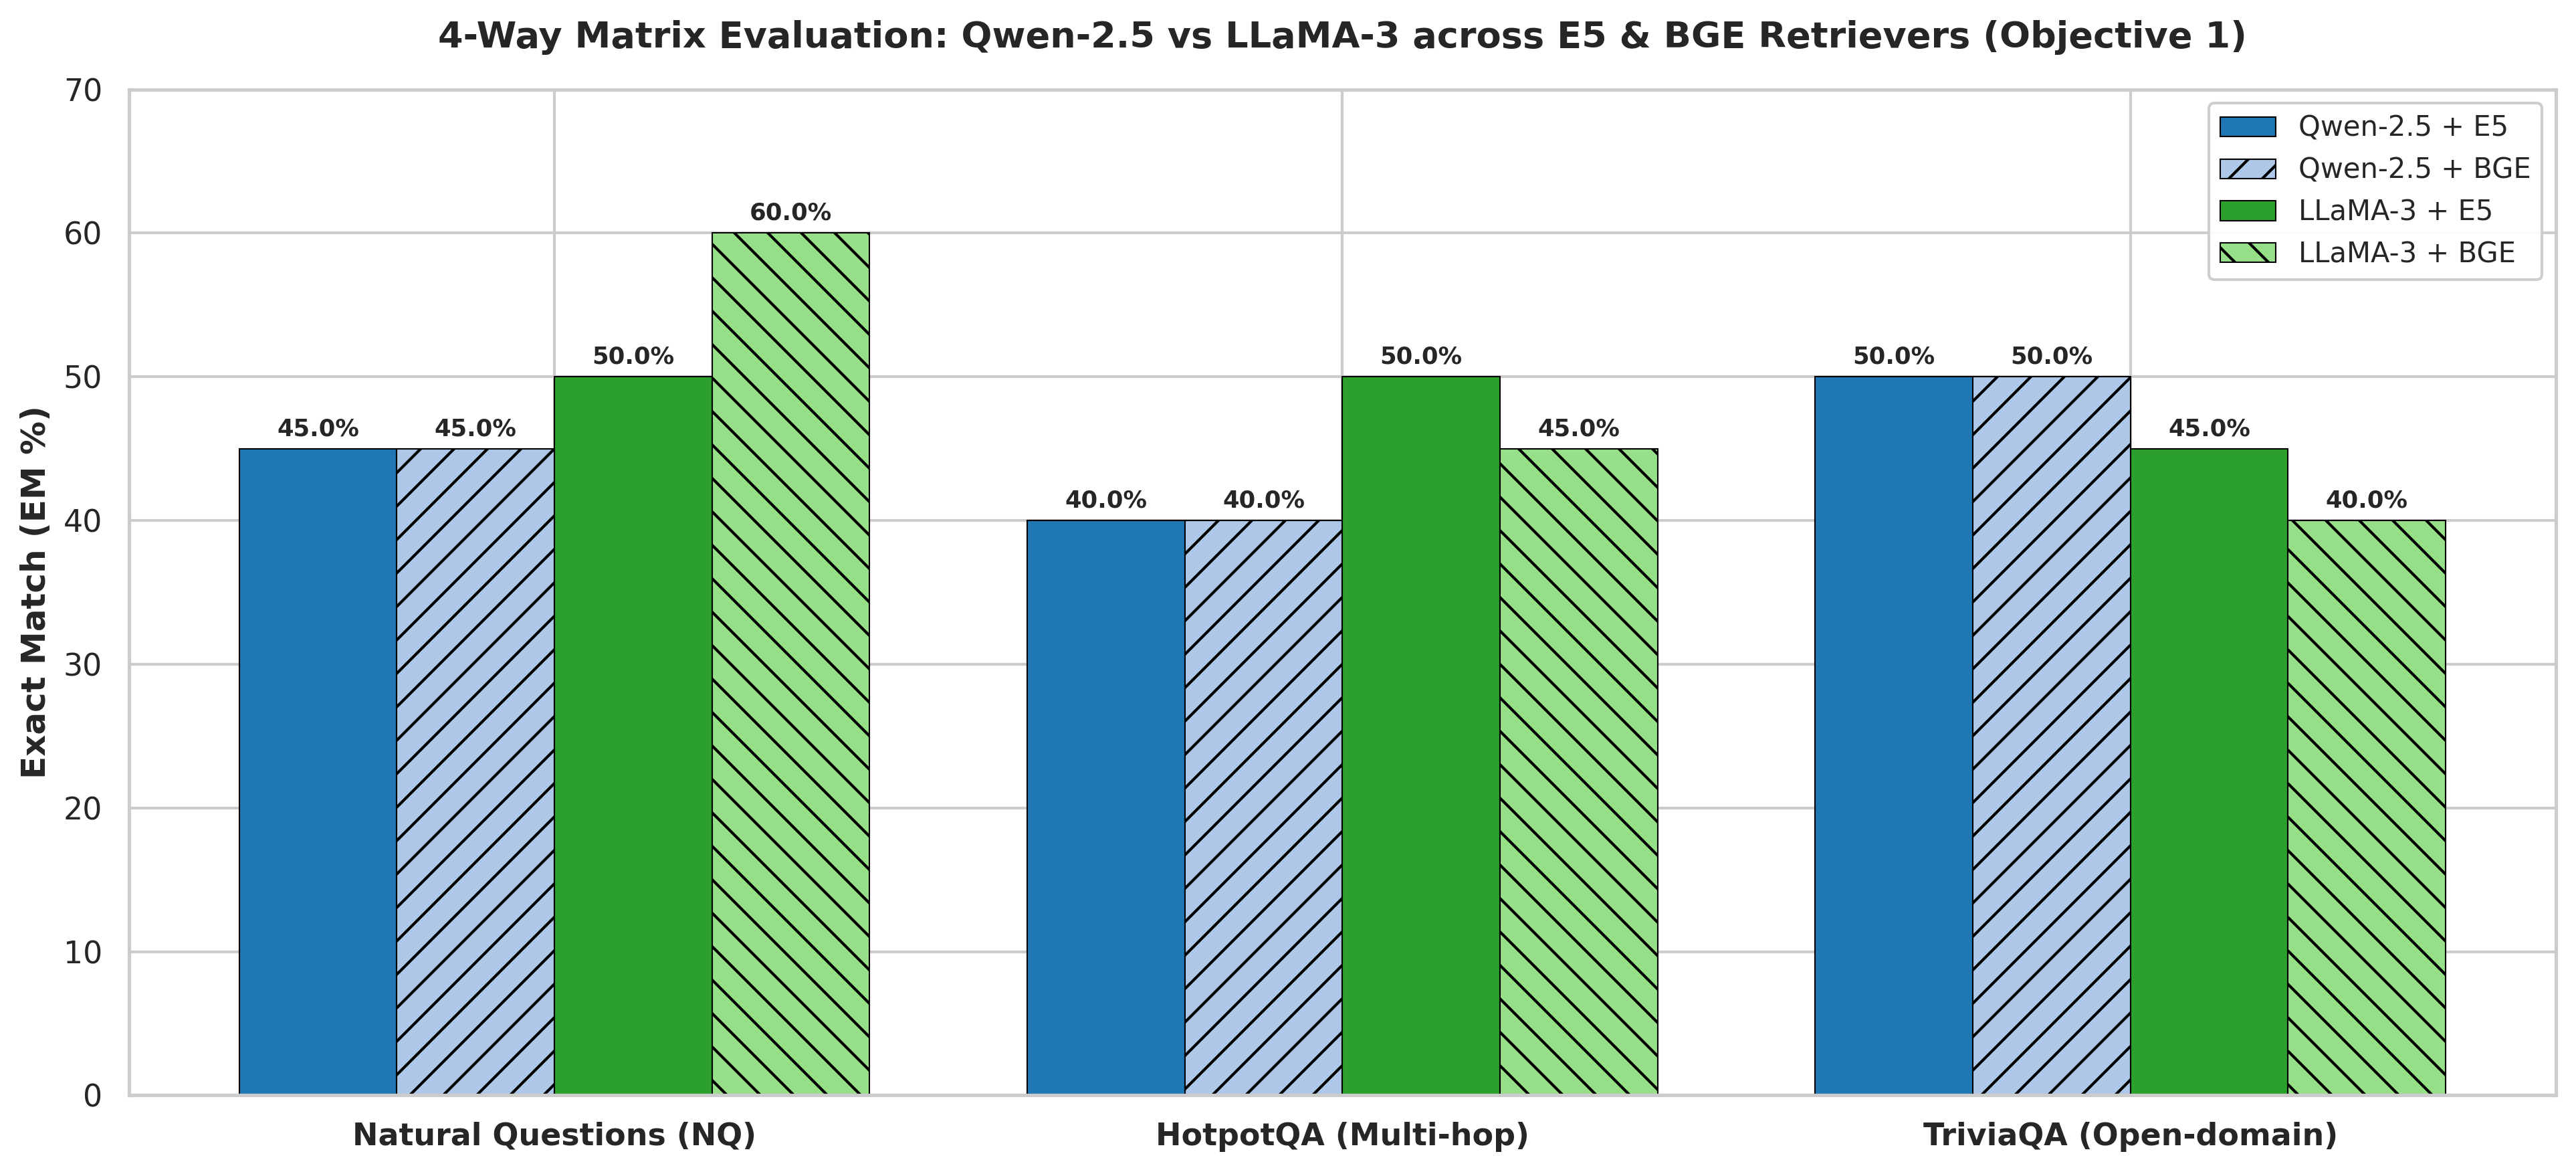

✅ Saved 4-Way Comparison Graph to: /content/drive/My Drive/Objective 1/results/figure7_4way_matrix_comparison.png


In [ ]:
# ==============================================================================
# 4-WAY EXPERIMENTAL MATRIX GRAPH (QWEN vs LLAMA & E5 vs BGE)
# ==============================================================================
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.sans-serif': 'DejaVu Sans', 'font.family': 'sans-serif'})

datasets = ['Natural Questions (NQ)', 'HotpotQA (Multi-hop)', 'TriviaQA (Open-domain)']
x = np.arange(len(datasets))
width = 0.20

# 4 Configuration Results
qwen_e5   = [45.00, 40.00, 50.00]
qwen_bge  = [45.00, 40.00, 50.00]
llama_e5  = [50.00, 50.00, 45.00]
llama_bge = [60.00, 45.00, 40.00]

fig, ax = plt.subplots(figsize=(13, 6), dpi=300)

rects1 = ax.bar(x - width*1.5, qwen_e5,   width, label='Qwen-2.5 + E5',   color='#1f77b4', edgecolor='black', linewidth=0.5)
rects2 = ax.bar(x - width*0.5, qwen_bge,  width, label='Qwen-2.5 + BGE',  color='#aec7e8', edgecolor='black', linewidth=0.5, hatch='//')
rects3 = ax.bar(x + width*0.5, llama_e5,  width, label='LLaMA-3 + E5',   color='#2ca02c', edgecolor='black', linewidth=0.5)
rects4 = ax.bar(x + width*1.5, llama_bge, width, label='LLaMA-3 + BGE',  color='#98df8a', edgecolor='black', linewidth=0.5, hatch='\\\\')

ax.set_ylabel('Exact Match (EM %)', fontsize=12, fontweight='bold')
ax.set_ylim(0, 70)
ax.set_xticks(x)
ax.set_xticklabels(datasets, fontsize=11, fontweight='bold')
ax.set_title('4-Way Matrix Evaluation: Qwen-2.5 vs LLaMA-3 across E5 & BGE Retrievers (Objective 1)', fontsize=13, fontweight='bold', pad=15)

def annotate_bars(rects):
    for rect in rects:
        h = rect.get_height()
        ax.annotate(f'{h:.1f}%',
                    xy=(rect.get_x() + rect.get_width() / 2, h),
                    xytext=(0, 3),
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=8.5, fontweight='bold')

annotate_bars(rects1)
annotate_bars(rects2)
annotate_bars(rects3)
annotate_bars(rects4)

ax.legend(loc='upper right', frameon=True, framealpha=0.95, fontsize=10)
plt.tight_layout()

save_path_4way = '/content/drive/My Drive/Objective 1/results/figure7_4way_matrix_comparison.png'
os.makedirs(os.path.dirname(save_path_4way), exist_ok=True)
plt.savefig(save_path_4way, bbox_inches='tight', dpi=300)
plt.show()
print(f"✅ Saved 4-Way Comparison Graph to: {save_path_4way}")